# Tutorial #
Welcome to my code! This notebook is meant to be an introduction into the computation of Relative Periodic Orbits (RPOs) in 2D magnetohydrodynamics (MHD).

## MHD ##
The magnetohydrodynamics (MHD) equations considered here are incompressible, so we have two constraints
$$
\nabla \cdot {\bf u} = 0,
$$
$$
\nabla \cdot {\bf B} = 0.
$$
These constraints are preserved by the MHD equations of motion
$$
\partial_t {\bf u} + \nabla \cdot ( {\bf u u} - {\bf BB}) + \nabla \tilde{p} = \nu \nabla^2 {\bf u} + {\bf f},
$$
$$
\partial_t {\bf B} + \nabla \cdot ({\bf uB} - {\bf Bu}) = \eta \nabla^2 {\bf B},
$$
where $\tilde{p}$ is the total pressure, $\nu$ is the kinematic viscosity, ${\bf f}$ is the body forcing, and $\eta$ is the resistivity. To make our lives easier, I wrote this code to solve the equations in the vorticity formulation, in which I evolve the curls of these fields.
$$
\omega = \partial_x u_y - \partial_y u_x,
$$
$$ 
j = \partial_x B_y - \partial_y B_x.
$$
The equations of motion are fairly simple compared to the vector formulation. If you are new to this method, I encourage you to work out these equations of motion yourself.
$$
\partial_t \omega + {\bf u} \cdot \nabla \omega - {\bf B} \cdot \nabla j = \nu \nabla^2 \omega + f_\omega,
$$
$$
\partial_t j + \nabla^2 ( u_x B_y - B_x u_y ) = \eta \nabla^2 j,
$$
where $f_\omega = \partial_x f_y - \partial_y f_x$ is the vorticity forcing. This is now a pressure-free formulation. For periodic boundary conditions, mapping from $\omega \rightarrow {\bf u}$ and $j \rightarrow {\bf B}$ is trivial in Fourier space. This makes this formulation rather attractive. I have focused on doubly periodic domains with $x,y\in[0,2\pi]^2$.


## Environment Setup ##
This repo uses [uv](https://docs.astral.sh/uv/) for package management. If you need to install uv, run
```bash
curl -LsSf https://astral.sh/uv/install.sh | sh
```
From the repo root (one directory up from this notebook), run in a terminal:
```bash
uv sync            # CPU
uv sync --extra cuda   # if you have an NVIDIA GPU + CUDA 12 drivers
```
Then launch this notebook with `uv run jupyter lab` (or point your existing Jupyter kernel at `.venv/bin/python`).

In [1]:
# confirm jax is installed correctly and see what devices it sees.
# If you installed `uv sync --extra cuda` on a GPU machine, you should see a CudaDevice below.
# If you see only CpuDevice, jax is falling back to CPU (check your CUDA drivers / the install extra used).
import jax
print("jax version:", jax.__version__)
print("Devices:", jax.devices())
print("Default backend:", jax.default_backend())

jax version: 0.12.0
Devices: [CpuDevice(id=0)]
Default backend: cpu


Jax is using [CpuDevice(id=0)]



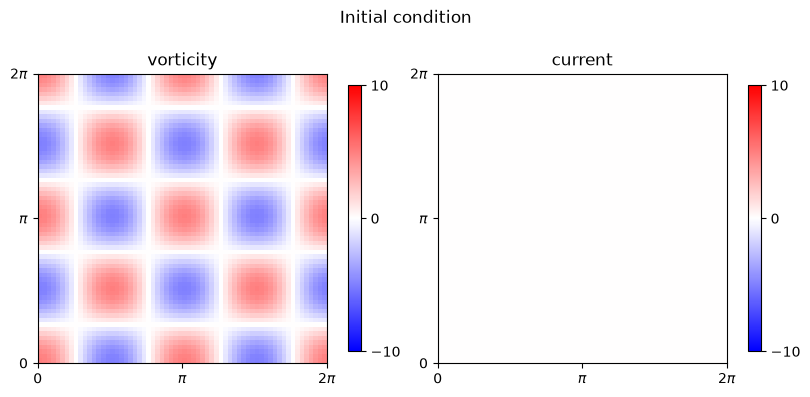

In [2]:
%load_ext autoreload
%autoreload 2

import lib.mhd_jax as mhd_jax
import lib.utils as utils
import jax.numpy as jnp

# Note the the symmetry machinery of the code currently assumes the mean magnetic field
# points only along the y direction [0, By] and that the mean flow u0 vanishes. Further, the spatial
# symmetries are designed for the forcing ~cos(4y).

n    = 64               # grid resolution (n x n)
nu   = 1/40             # fluid dissipation
eta  = 1/40             # magnetic dissipation
b0   = [0.0, 0.1]       # mean magnetic field
u0   = [0.0, 0.0]       # mean flow field
seed = 111              # RNG seed for the random initial condition

# Forcing is specified as a string defining a lambda(x,y) -> vorticity forcing.
# Here: Kolmogorov forcing at wavenumber 4.
forcing_str = "lambda x,y : -4*jnp.cos(4*y)"

###############################
# Everything else (grid construction, dealiasing, random field generation)
# is handled for you inside utils.initialize_system
###############################
f0, param_dict = utils.initialize_system(n, nu, eta, b0, u0, seed, forcing_str)

#Overwrite the random intiial condition with an analytic function
x, y = param_dict["x"], param_dict["y"]
f0 = f0.at[0,:,:].set( 5*jnp.cos(2*x)*jnp.cos(2*y) )   #initial vorticity
f0 = f0.at[1,:,:].set( 0*x )                           #initial current 

figure, axis = mhd_jax.vis(f0, in_spectral=False, title="Initial condition")

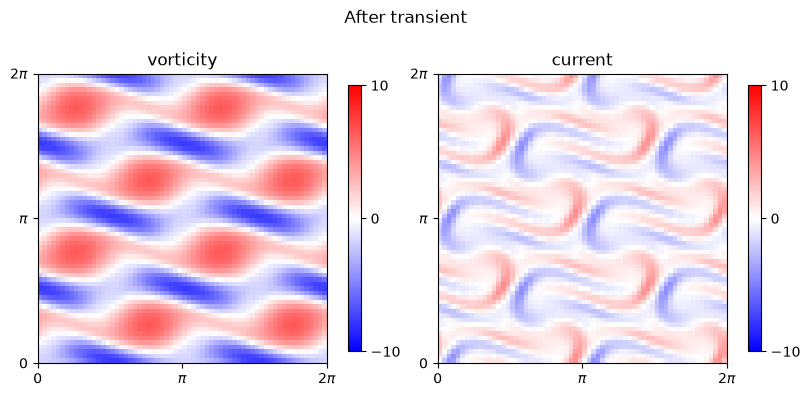

In [3]:
# Evolve a transient so our random initial condition relaxes onto the turbulent attractor.

dt = 1/128            # timestep
transient_time = 2.0  # total time to integrate the transient for

f = utils.evolve_transient(f0, param_dict, dt, transient_time)

figure, axis = mhd_jax.vis(f, in_spectral=True, title="After transient")

In [4]:
# Now that we have a sensible initial condition, integrate to build a timeseries
# and compute a recurrence diagram -- near-recurrences make good RPO guesses.

dt = 1/128
micro_steps = 16  # timesteps between saving
macro_steps = 256  # number of saved states

fs, dist = utils.generate_turbulent_trajectory(f, param_dict, dt, macro_steps, micro_steps)

Generating 256 steps of turbulence took 0.14184832572937012 seconds.
Recurrence diagram computed in 3.6488475799560547 seconds


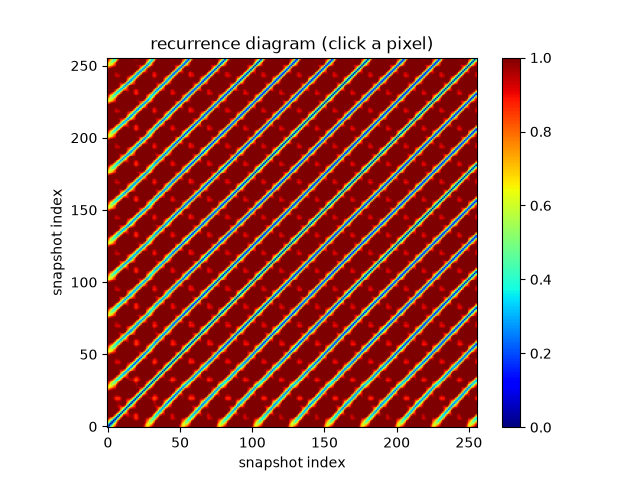

In [5]:
%matplotlib widget
# Bright streaks off the diagonal indicate near-recurrences -- good candidates for RPO guesses.
figure = utils.plot_recurrence_diagram(dist)

In [7]:
#Now we can make a guess at a recurrence. Zoom into the recurrence diagram near the
#diagonal: a dark pixel a short distance off the diagonal is a near-recurrence, a good
#RPO guess. Here we picked one by hand at i=152, j=170 this way.

idx = [19, 41]

#Append timestepping information as well
param_dict.update( {'dt': dt, 'ministeps': micro_steps, 'steps': macro_steps} )
turb_dict = {'fs': fs}
input_dict, param_dict = utils.create_state_from_turb(turb_dict, idx, param_dict)

Best symmetry found is (0.0, 2, True)


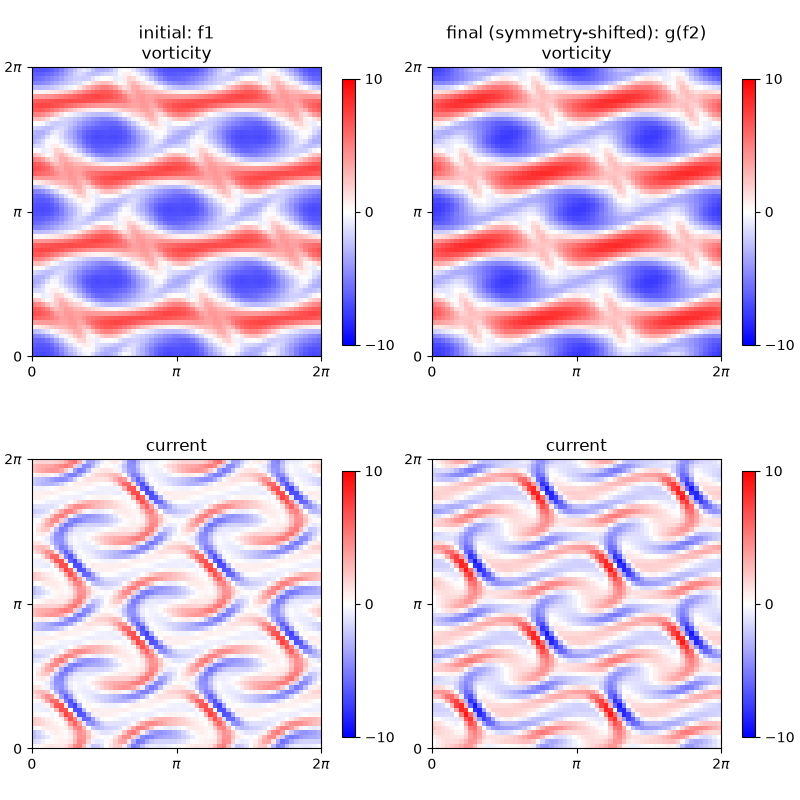

In [8]:
# Sanity check the guess: the initial snapshot and the symmetry-shifted final
# snapshot should look nearly identical if this is a good RPO candidate.
figure, axis = utils.compare_initial_final(turb_dict, idx, input_dict, param_dict)

In [10]:
#For fixed timestep solvers, we need to define parameters for checkpointing.
ministeps = 8
assert( param_dict['steps'] % ministeps == 0 )
param_dict.update({"ministeps": ministeps, "num_checkpoints": param_dict['steps']//ministeps })

maxit = 32          # number of ADAM steps
lr = 1e-2            # ADAM learning rate
save_every = 8       # checkpoint to disk every this many steps
min_abs_T = 0.3      # floor |T| away from 0 -- the loss has an exact minimum at T=0
                     # for any field (zero-duration integration is trivially the
                     # identity), so unconstrained descent would collapse there.

input_dict, history = utils.run_adjoint_descent(input_dict, param_dict, maxit=maxit, lr=lr,
                                                  save_every=save_every, min_abs_T=min_abs_T)

0: loss=3.120550, walltime=0.702, T=2.760, sx=0.000
1: loss=2.808906, walltime=0.000, T=2.770, sx=-0.001
2: loss=2.501532, walltime=0.000, T=2.780, sx=0.005
3: loss=2.205409, walltime=0.000, T=2.790, sx=0.001
4: loss=1.913344, walltime=0.001, T=2.800, sx=-0.004
5: loss=1.642364, walltime=0.000, T=2.810, sx=-0.004
6: loss=1.387474, walltime=0.000, T=2.820, sx=-0.001
7: loss=1.152189, walltime=0.000, T=2.829, sx=0.002
8: loss=0.943448, walltime=0.000, T=2.839, sx=0.003
9: loss=0.761063, walltime=0.000, T=2.849, sx=0.002
10: loss=0.603390, walltime=0.000, T=2.858, sx=-0.000
11: loss=0.472778, walltime=0.000, T=2.867, sx=-0.002
12: loss=0.370057, walltime=0.000, T=2.876, sx=-0.003
13: loss=0.291958, walltime=0.000, T=2.884, sx=-0.002
14: loss=0.235384, walltime=0.000, T=2.892, sx=0.000
15: loss=0.199066, walltime=0.000, T=2.899, sx=0.002
16: loss=0.180535, walltime=0.000, T=2.906, sx=0.002
17: loss=0.175270, walltime=0.000, T=2.912, sx=0.001
18: loss=0.179381, walltime=0.000, T=2.918, sx=-

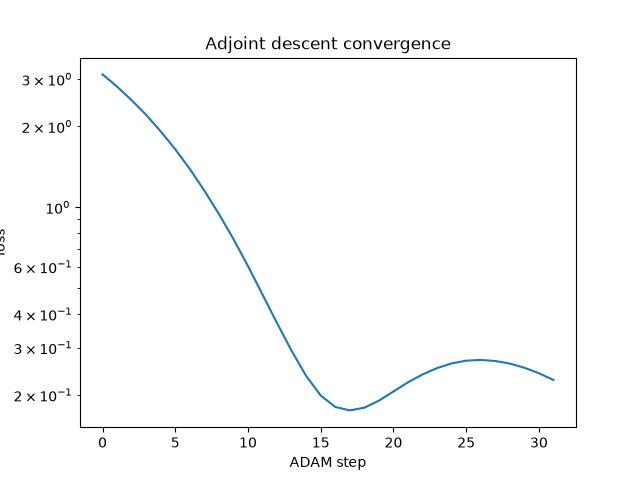

In [11]:
import matplotlib.pyplot as plt
plt.figure()
plt.semilogy(history)
plt.xlabel("ADAM step")
plt.ylabel("loss")
plt.title("Adjoint descent convergence")
plt.show()

## Newton vs Gauss-Newton ##
Adjoint descent gets us close, but convergence slows down a lot near the solution. We now fine-tune with Newton-GMRES.

Both variants solve the same Newton step with GMRES, computing Jacobian actions via `jax.jvp`. The only difference is `use_transpose`:
- **Newton** (`use_transpose=False`): solve $Js = -f$ directly.
- **Gauss-Newton** (`use_transpose=True`): precondition GMRES with the Jacobian transpose, equivalent to solving the normal equations $(J^TJ)s = -J^Tf$.

Gauss-Newton typically needs far fewer Krylov directions per step and tolerates larger steps, at the cost of being a descent method (it can in principle stall at a local minimum of $|f|^2$ rather than a true root).

In [14]:
import copy

#newton_input_dict, newton_param_dict = utils.load_latest_checkpoint("temp_data/adjoint_descent")
newton_input_dict, newton_param_dict = input_dict, param_dict

###############################
# Newton / Gauss-Newton parameters -- the only things you need to touch
###############################

maxit = 6     # number of Newton/Gauss-Newton steps
inner = 16    # GMRES Krylov subspace dimension -- small on purpose, to show
              # Gauss-Newton tolerating it while plain Newton struggles
mode = "RK4"  # timestepping scheme used inside the objective
min_abs_T = 0.3  # same trivial-root issue as adjoint descent -- GN/Newton's own
                 # root-finding can also walk into the T=0 solution, so floor it here too

newton_out, newton_history = utils.run_newton(
    copy.deepcopy(newton_input_dict), copy.deepcopy(newton_param_dict),
    use_transpose=False, maxit=maxit, inner=inner, mode=mode, min_abs_T=min_abs_T)

Evaluating objective: 3.24e-05 seconds
Evaluating Jacobian: 3.15e-05 seconds
0: rel_err=1.269e-01, |f|=4.181e+01, gmres_rel_res=1.680e-07, T=3.052, sx=-0.000
1: rel_err=6.906e-02, |f|=2.217e+01, gmres_rel_res=6.339e-05, T=3.083, sx=0.000
2: rel_err=3.219e-03, |f|=1.032e+00, gmres_rel_res=1.959e-03, T=3.085, sx=0.000
3: rel_err=6.565e-06, |f|=2.105e-03, gmres_rel_res=4.294e-02, T=3.085, sx=0.000
4: rel_err=2.819e-07, |f|=9.038e-05, gmres_rel_res=3.966e-02, T=3.085, sx=0.000
5: rel_err=1.118e-08, |f|=3.585e-06, gmres_rel_res=9.997e-02, T=3.085, sx=0.000


In [ ]:
import lib.dictionaryIO as dictionaryIO

#Save to npz file for animation
dictionaryIO.save_dicts( f"temp_data/tutorial_output", newton_out, newton_param_dict )